In [1]:
%pip install openpyxl

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_excel("youtube_ad_revenue_dataset.xlsx")
print(df.shape)
df.head()

(122400, 12)


,video_id,date,views,likes,comments,watch_time_minutes,video_length_minutes,subscribers,category,device,country,ad_revenue_usd
0,vid_3092,2024-09-24 10:50:40.993,9936,1221.0,320.0,26497.214184,2.862137,228086,Entertainment,TV,IN,203.178237
1,vid_3459,2024-09-22 10:50:40.993,10017,642.0,346.0,15209.747445,23.738069,736015,Gaming,Tablet,CA,140.880508
2,vid_4784,2024-11-21 10:50:40.993,10097,1979.0,187.0,57332.658498,26.200634,240534,Education,TV,CA,360.134008
3,vid_4078,2025-01-28 10:50:40.993,10034,1191.0,242.0,31334.517771,11.770340,434482,Entertainment,Mobile,UK,224.638261
4,vid_3522,2025-04-28 10:50:40.993,9889,1858.0,477.0,15665.666434,6.635854,42030,Education,Mobile,CA,165.514388


In [4]:
%pip install pandas numpy matplotlib seaborn scikit-learn joblib openpyxl

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 122400 entries, 0 to 122399
Data columns (total 12 columns):
 #   Column                Non-Null Count   Dtype         
---  ------                --------------   -----         
 0   video_id              122400 non-null  object        
 1   date                  122400 non-null  datetime64[ns]
 2   views                 122400 non-null  int64         
 3   likes                 116283 non-null  float64       
 4   comments              116288 non-null  float64       
 5   watch_time_minutes    116295 non-null  float64       
 6   video_length_minutes  122400 non-null  float64       
 7   subscribers           122400 non-null  int64         
 8   category              122400 non-null  object        
 9   device                122400 non-null  object        
 10  country               122400 non-null  object        
 11  ad_revenue_usd        122400 non-null  float64       
dtypes: datetime64[ns](1), float64(5), int64(2), object(4)
memo

In [6]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
date,122400,2024-12-08 04:34:02.169470976,2024-06-09 10:50:40.993000,2024-09-07 10:50:40.992999936,2024-12-08 10:50:40.992999936,2025-03-09 10:50:40.992999936,2025-06-08 10:50:40.993000,NaN
views,122400.0,9999.856283,9521.0,9933.0,10000.0,10067.0,10468.0,99.88126
likes,116283.0,1099.633618,195.0,650.0,1103.0,1547.0,2061.0,519.424089
comments,116288.0,274.396636,48.0,162.0,274.0,387.0,515.0,129.741739
watch_time_minutes,116295.0,37543.827721,14659.105562,26366.320569,37531.990337,48777.78209,61557.670089,12987.724246
video_length_minutes,122400.0,16.014165,2.000142,9.004695,16.005906,23.02126,29.999799,8.08379
subscribers,122400.0,502191.719902,1005.0,252507.5,503465.5,752192.0,999997.0,288397.470103
ad_revenue_usd,122400.0,252.72721,126.590603,199.902018,252.749699,305.597518,382.768254,61.957052


In [7]:
print(df.isna().sum())
print("duplicates:", df.duplicated().sum())

video_id                   0
date                       0
views                      0
likes                   6117
comments                6112
watch_time_minutes      6105
video_length_minutes       0
subscribers                0
category                   0
device                     0
country                    0
ad_revenue_usd             0
dtype: int64
duplicates: 2400


In [8]:
missing_pct = (df.isna().sum() / len(df) * 100).round(2)
print(missing_pct[missing_pct > 0])

likes                 5.00
comments              4.99
watch_time_minutes    4.99
dtype: float64


In [9]:
##clean the Data ##
# Remove exact duplicate rows and renumber the index#
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)
print("Duplicates left:", df.duplicated().sum())

Shape after removing duplicates: (120000, 12)
Duplicates left: 0


In [10]:
# Percentage of missing values per column
missing_pct = (df.isna().mean() * 100).round(2)
print(missing_pct[missing_pct > 0])

# Medians we will use later for imputation
print(df[["likes", "comments", "watch_time_minutes"]].median())

likes                 5.0
comments              5.0
watch_time_minutes    5.0
dtype: float64
likes                  1102.000000
comments                274.000000
watch_time_minutes    37522.221205
dtype: float64


In [11]:
###Feature engineering###
##Ratio features##
# Engagement features: normalise raw counts by the number of views
df["engagement_rate"] = (df["likes"] + df["comments"]) / df["views"]
df["like_rate"] = df["likes"] / df["views"]
df["comment_rate"] = df["comments"] / df["views"]
df["watch_time_per_view"] = df["watch_time_minutes"] / df["views"]

In [12]:
##Date features##
# Extract calendar information from the date column
df["month"] = df["date"].dt.month
df["day_of_week"] = df["date"].dt.dayofweek   # Monday = 0 ... Sunday = 6

In [13]:
new_cols = ["views", "likes", "comments", "watch_time_minutes", "engagement_rate",
            "like_rate", "comment_rate", "watch_time_per_view", "month", "day_of_week"]
print(df[new_cols].head())
print(df[new_cols].isna().sum())
print(df[["engagement_rate", "like_rate", "comment_rate", "watch_time_per_view"]].describe().T)

   views   likes  comments  watch_time_minutes  engagement_rate  like_rate  \
0   9936  1221.0     320.0        26497.214184         0.155093   0.122886   
1  10017   642.0     346.0        15209.747445         0.098632   0.064091   
2  10097  1979.0     187.0        57332.658498         0.214519   0.195999   
3  10034  1191.0     242.0        31334.517771         0.142814   0.118696   
4   9889  1858.0     477.0        15665.666434         0.236121   0.187886   

   comment_rate  watch_time_per_view  month  day_of_week  
0      0.032206             2.666789      9            1  
1      0.034541             1.518393      9            6  
2      0.018520             5.678187     11            3  
3      0.024118             3.122834      1            1  
4      0.048235             1.584151      4            0  
views                      0
likes                   6000
comments                6000
watch_time_minutes      6000
engagement_rate        11696
like_rate               6000
com

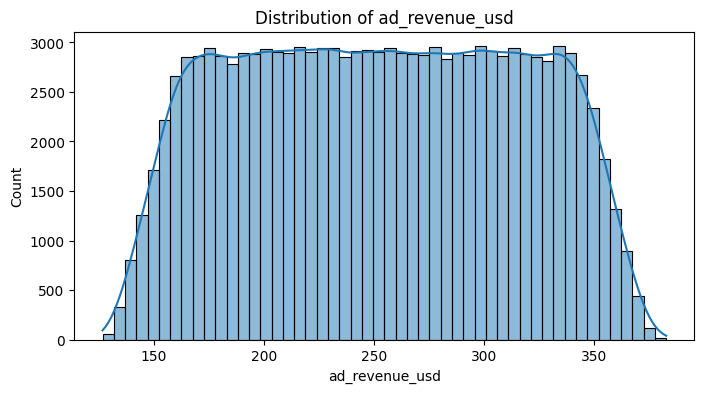

count    120000.000000
mean        252.711361
std          61.954125
min         126.590603
25%         199.892158
50%         252.678607
75%         305.613497
max         382.768254
Name: ad_revenue_usd, dtype: float64


In [14]:
##EDA (Exploratory Data Analysis)##

plt.figure(figsize=(8, 4))
sns.histplot(df["ad_revenue_usd"], bins=50, kde=True)
plt.title("Distribution of ad_revenue_usd")
plt.show()

print(df["ad_revenue_usd"].describe())

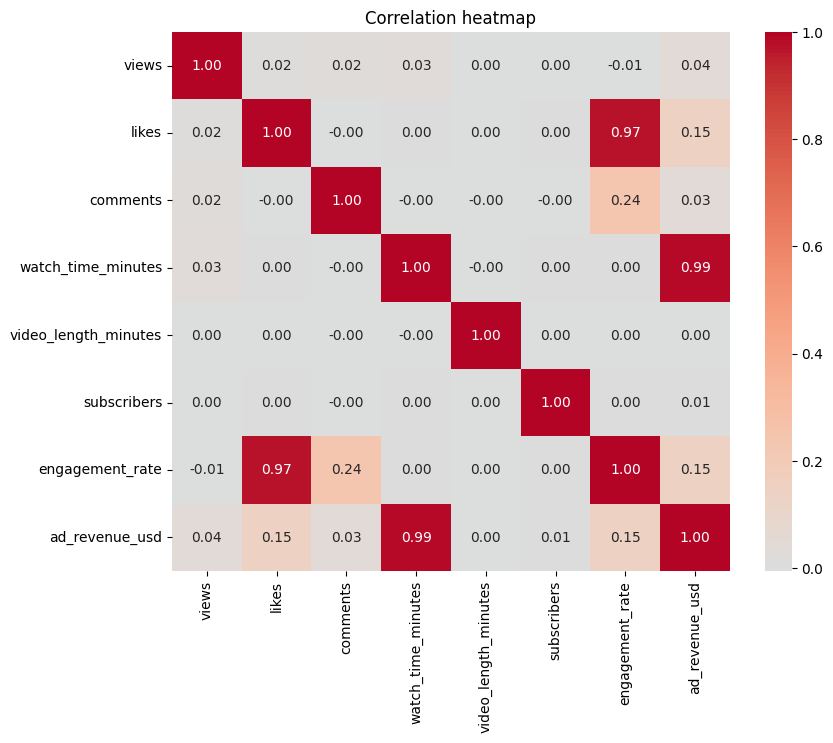

In [15]:
#Correlation heatmap#
cols = ["views", "likes", "comments", "watch_time_minutes", "video_length_minutes",
        "subscribers", "engagement_rate", "ad_revenue_usd"]
plt.figure(figsize=(9, 7))
sns.heatmap(df[cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap")
plt.show()

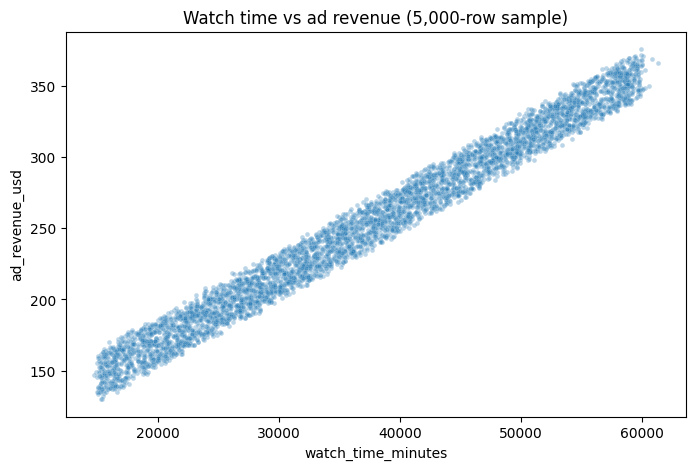

In [16]:
#Watch time vs revenue scatter#
sample = df.sample(5000, random_state=42)
plt.figure(figsize=(8, 5))
sns.scatterplot(data=sample, x="watch_time_minutes", y="ad_revenue_usd", alpha=0.3, s=12)
plt.title("Watch time vs ad revenue (5,000-row sample)")
plt.show()

category
Education        252.56
Entertainment    252.40
Gaming           253.43
Lifestyle        251.94
Music            252.48
Tech             253.46
Name: ad_revenue_usd, dtype: float64 

device
Desktop    252.28
Mobile     253.24
TV         252.33
Tablet     252.99
Name: ad_revenue_usd, dtype: float64 

country
AU    252.46
CA    252.83
DE    252.75
IN    252.49
UK    252.56
US    253.18
Name: ad_revenue_usd, dtype: float64 



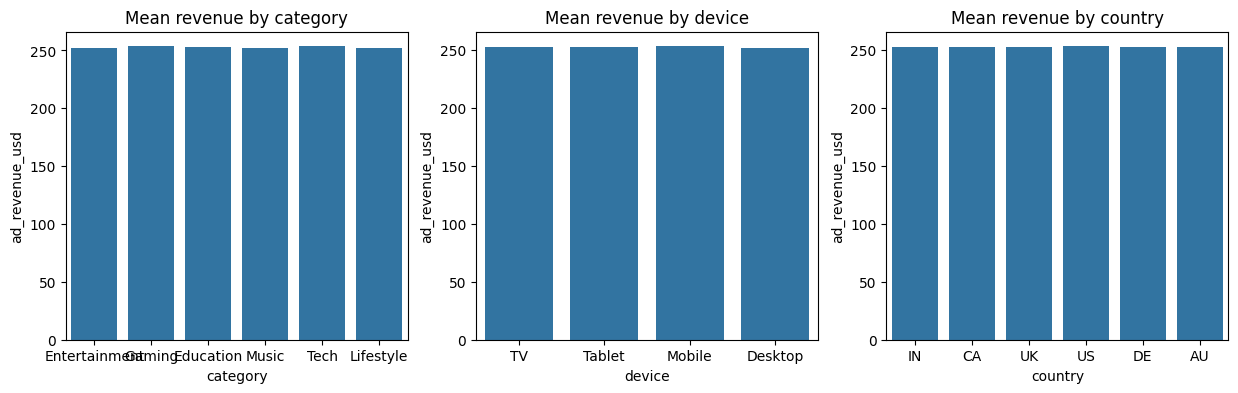

In [17]:
#Category, device, country, revenue#
for col in ["category", "device", "country"]:
    print(df.groupby(col)["ad_revenue_usd"].mean().round(2), "\n")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["category", "device", "country"]):
    sns.barplot(data=df, x=col, y="ad_revenue_usd", ax=ax, errorbar=None)
    ax.set_title(f"Mean revenue by {col}")
plt.show()

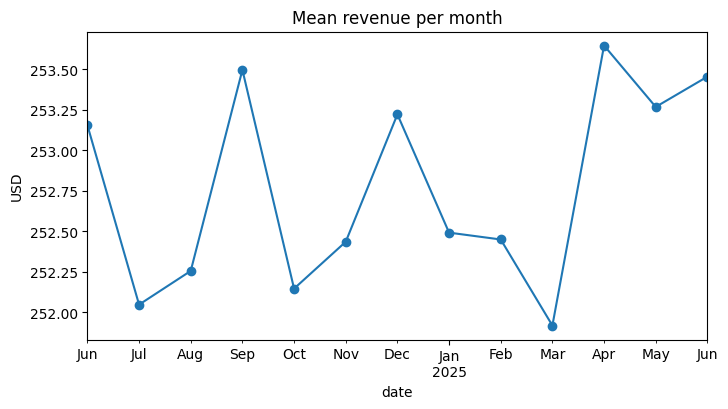

In [18]:
monthly = df.groupby(df["date"].dt.to_period("M"))["ad_revenue_usd"].mean()
monthly.plot(marker="o", figsize=(8, 4), title="Mean revenue per month")
plt.ylabel("USD")
plt.show()

In [19]:
#Train/test split and preprocessing pipeline#
#Libraries import#
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder


In [20]:
#Features and target#
numeric = ["views", "likes", "comments", "watch_time_minutes", "video_length_minutes",
           "subscribers", "engagement_rate", "like_rate", "comment_rate",
           "watch_time_per_view", "month", "day_of_week"]
categorical = ["category", "device", "country"]

X = df[numeric + categorical]    # input columns (features)
y = df["ad_revenue_usd"]         # the value we want to predict (target)
print(X.shape, y.shape)

(120000, 15) (120000,)


In [21]:
##Train/test split##
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(96000, 15) (24000, 15)


In [22]:
##Preprocessing pipeline##
numeric_steps = Pipeline([
    ("impute", SimpleImputer(strategy="median")),   # fill missing with the median
    ("scale", StandardScaler()),                    # put numbers on a similar scale
])

preprocess = ColumnTransformer([
    ("num", numeric_steps, numeric),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), categorical),
])

In [23]:
check = preprocess.fit_transform(X_train)
print("Transformed shape:", check.shape)
print(preprocess.get_feature_names_out())

Transformed shape: (96000, 25)
['num__views' 'num__likes' 'num__comments' 'num__watch_time_minutes'
 'num__video_length_minutes' 'num__subscribers' 'num__engagement_rate'
 'num__like_rate' 'num__comment_rate' 'num__watch_time_per_view'
 'num__month' 'num__day_of_week' 'cat__category_Entertainment'
 'cat__category_Gaming' 'cat__category_Lifestyle' 'cat__category_Music'
 'cat__category_Tech' 'cat__device_Mobile' 'cat__device_TV'
 'cat__device_Tablet' 'cat__country_CA' 'cat__country_DE'
 'cat__country_IN' 'cat__country_UK' 'cat__country_US']


In [24]:
##models##
#Imports#
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [25]:
#Models#
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Lasso Regression": Lasso(alpha=0.01),
    "Random Forest": RandomForestRegressor(n_estimators=60, max_depth=10,
                                           min_samples_leaf=10, n_jobs=-1, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=100, max_depth=3,
                                                   random_state=42),
}

In [26]:
fitted, rows = {}, []
for name, est in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", est)])   # preprocessing + model together
    pipe.fit(X_train, y_train)                                # learn from training data
    pred = pipe.predict(X_test)                               # predict on unseen test data
    fitted[name] = pipe
    rows.append({
        "model": name,
        "R2": r2_score(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "MAE": mean_absolute_error(y_test, pred),
    })
    print("done:", name)

results = pd.DataFrame(rows).sort_values("R2", ascending=False)
results.round(4)

done: Linear Regression
done: Ridge Regression
done: Lasso Regression
done: Random Forest
done: Gradient Boosting


,model,R2,RMSE,MAE
2,Lasso Regression,0.9526,13.4781,3.0821
0,Linear Regression,0.9526,13.4832,3.1545
1,Ridge Regression,0.9526,13.4834,3.1589
4,Gradient Boosting,0.9522,13.5367,3.7105
3,Random Forest,0.9517,13.6004,3.8046


In [27]:
##Evaluation and error analysis##
#Cross-validation#
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression

lr = fitted["Linear Regression"]          # the trained Linear Regression pipeline
cv_pipe = Pipeline([("prep", preprocess), ("model", LinearRegression())])
cv_scores = cross_val_score(cv_pipe, X_train, y_train, cv=5, scoring="r2")
print("Fold scores:", cv_scores.round(4))
print(f"Mean R2: {cv_scores.mean():.4f} +/- {cv_scores.std():.4f}")

Fold scores: [0.9509 0.9513 0.9473 0.9486 0.9504]
Mean R2: 0.9497 +/- 0.0015


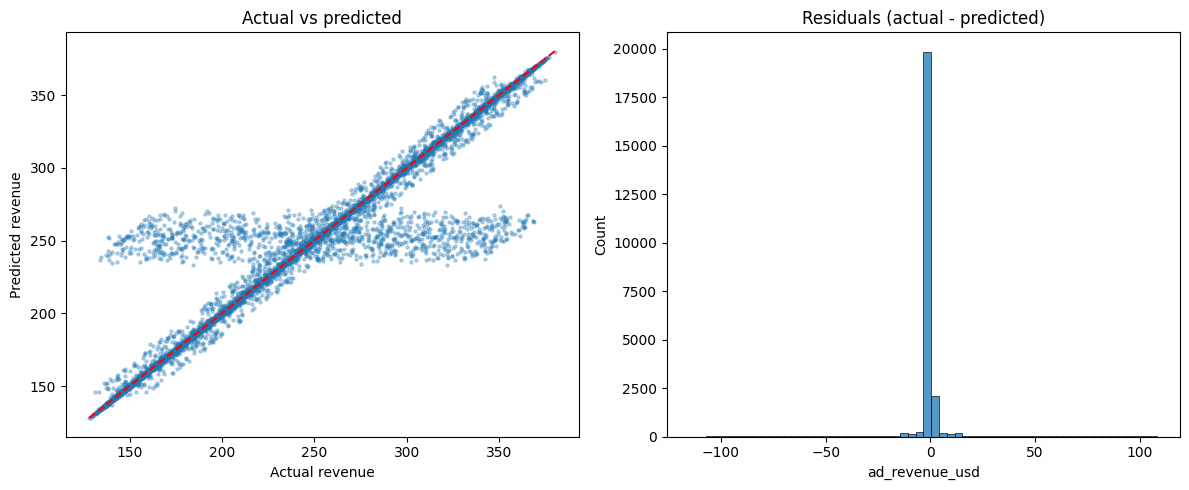

In [28]:
#Actual vs predicted, and residuals#
pred = lr.predict(X_test)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].scatter(y_test, pred, s=5, alpha=0.3)
ax[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
ax[0].set(xlabel="Actual revenue", ylabel="Predicted revenue", title="Actual vs predicted")

sns.histplot(y_test - pred, bins=60, ax=ax[1])
ax[1].set_title("Residuals (actual - predicted)")
plt.tight_layout()
plt.show()

In [29]:
#Investigate the flat band#
no_wt = X_test["watch_time_minutes"].isna()      # True where watch time was missing

for label, mask in [("watch time present", ~no_wt), ("watch time missing", no_wt)]:
    p = lr.predict(X_test[mask])
    print(f"{label:20s} rows={mask.sum():6d}  "
          f"R2={r2_score(y_test[mask], p):.4f}  "
          f"MAE=${mean_absolute_error(y_test[mask], p):.2f}")

watch time present   rows= 22859  R2=0.9988  MAE=$0.69
watch time missing   rows=  1141  R2=0.0211  MAE=$52.58


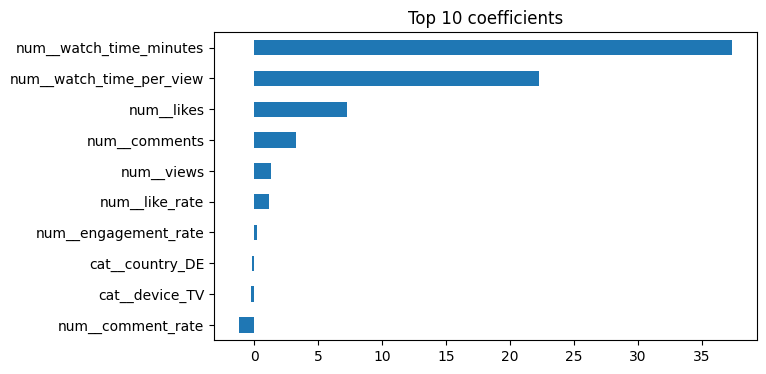

num__watch_time_minutes     37.380
num__watch_time_per_view    22.296
num__likes                   7.252
num__comments                3.275
num__views                   1.292
num__comment_rate           -1.208
num__like_rate               1.162
num__engagement_rate         0.253
cat__device_TV              -0.237
cat__country_DE             -0.133
dtype: float64


In [30]:
#Which features matter? (coefficients)#
names = lr.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(lr.named_steps["model"].coef_, index=names)
coefs = coefs.sort_values(key=abs, ascending=False)

coefs.head(10).sort_values().plot(kind="barh", figsize=(7, 4),
                                  title="Top 10 coefficients")
plt.show()
print(coefs.head(10).round(3))

In [31]:
#Save the model and the cleaned dataset#
#Save the trained model#
import joblib
import os

os.makedirs("youtube_revenue_project/Models", exist_ok=True)
joblib.dump(lr, "youtube_revenue_project/Models/revenue_model.pkl")
print("Model saved")

Model saved


In [32]:
#est that the saved model works#
loaded = joblib.load("youtube_revenue_project/Models/revenue_model.pkl")
print(loaded.predict(X_test.iloc[:3]))
print(lr.predict(X_test.iloc[:3]))
print(y_test.iloc[:3].values)

[352.93403702 341.8775257  204.35153354]
[352.93403702 341.8775257  204.35153354]
[352.85352072 341.98378848 204.58688315]


In [33]:
#Save the cleaned dataset#
clean = df.drop(columns=["engagement_rate", "like_rate", "comment_rate",
                         "watch_time_per_view", "month", "day_of_week"]).copy()

for col in ["likes", "comments", "watch_time_minutes"]:
    clean[col] = clean[col].fillna(clean[col].median())

# rebuild the engineered features on the filled data
clean["engagement_rate"] = (clean["likes"] + clean["comments"]) / clean["views"]
clean["like_rate"] = clean["likes"] / clean["views"]
clean["comment_rate"] = clean["comments"] / clean["views"]
clean["watch_time_per_view"] = clean["watch_time_minutes"] / clean["views"]
clean["month"] = clean["date"].dt.month
clean["day_of_week"] = clean["date"].dt.dayofweek

os.makedirs("youtube_revenue_project/Data", exist_ok=True)
clean.to_csv("youtube_revenue_project/Data/cleaned_youtube_ad_revenue.csv", index=False)
print(clean.shape, clean.isna().sum().sum())

(120000, 18) 0


In [34]:
#Confirm the files exist#
print(os.listdir("youtube_revenue_project/Models"))
print(os.listdir("youtube_revenue_project/Data"))

['revenue_model.pkl']
['cleaned_youtube_ad_revenue.csv']


In [35]:
#Install Streamlit  in bash#
import sys
print(sys.executable)



c:\Users\Muthuramalingam A\AppData\Local\Python\pythoncore-3.14-64\python.exe
